# Property database quality — Python investigation

**Question:** Can missing working-copy fields be recovered using exact evidence while preserving questionable transactions for review?

The source records are real; **80 missing fields and one invalid proposal are deliberately simulated**. This notebook exposes the before/after analysis and rejection decisions. It does not require Streamlit and does not equate complete data with valid appraisal evidence.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/brooklyn_multifamily_sales.csv').exists(), 'Open from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


## 1. Load the verified source into an isolated database
A temporary database makes this notebook repeatable without overwriting an existing audit history.

In [2]:
import tempfile
from research import connect, initialize, seed_demo, quality, apply_proposal
workspace = tempfile.TemporaryDirectory(prefix='property_notebook_')
con = connect(Path(workspace.name)/'research.sqlite')
registry = initialize(con)
original = quality(con)
assert len(original)==sum(s['scope_rows'] for s in registry['sources'])
display(original[['sale_price','gross_square_feet','residential_units']].describe().round(2))
print('Source records:',len(original),'Original missing audited cells:',original.missing_fields.sum())


Source records: 2373 Original missing audited cells: 0


,sale_price,gross_square_feet,residential_units
count,2373.00,2373.00,2373.00
mean,1313186.82,5304.70,6.37
std,2965001.27,4708.44,5.47
min,0.00,0.00,0.00
25%,0.00,3200.00,4.00
50%,50000.00,4070.00,5.00
75%,1690000.00,5500.00,6.00
max,55000000.00,56000.00,73.00


## 2. Separate completeness from business-rule issues
A zero-price transfer is populated but may not provide usable price evidence. Rule counts overlap.

,flagged records; overlapping
invalid_area,5
possible_package,139
zero_or_negative_consideration,1073


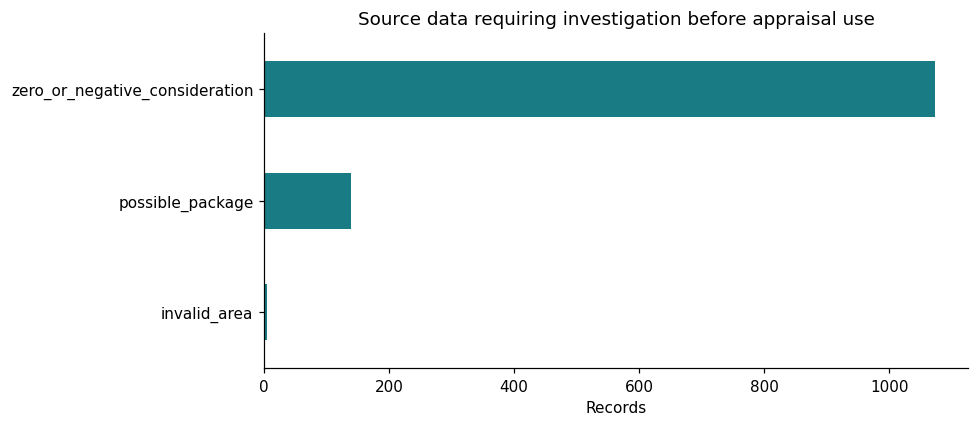

In [3]:
flags=['zero_or_negative_consideration','invalid_area','possible_package']
flag_counts=original[flags].sum().sort_values()
display(flag_counts.to_frame('flagged records; overlapping'))
flag_counts.plot.barh(color='#197b83',title='Source data requiring investigation before appraisal use')
plt.xlabel('Records');plt.tight_layout();plt.show()


## 3. Introduce controlled import gaps and measure the baseline
Exactly one field is removed from each of 80 working records. Original evidence is preserved. This is not a claim about actual provider errors.

In [4]:
seed_demo(con)
before=quality(con)
fields=['address','sale_price','gross_square_feet','residential_units']
missing_before=before[fields].isna().sum()
assert int(missing_before.sum())-int(original.missing_fields.sum())==80
display(missing_before.to_frame('missing before recovery'))
display(pd.read_sql_query('SELECT proposal_id,field,proposed_value,evidence_source,evidence_row,status FROM proposals LIMIT 6',con))


,missing before recovery
address,20
sale_price,20
gross_square_feet,20
residential_units,20


,proposal_id,field,proposed_value,evidence_source,evidence_row,status
0,DEMO-000,address,"408 THOMAS S. BOYLAND STREET, 3-3",nyc_dof_brooklyn_2024,16495,PENDING
1,DEMO-001,sale_price,1680000.0,nyc_dof_brooklyn_2024,20113,PENDING
2,DEMO-002,gross_square_feet,2830.0,nyc_dof_brooklyn_2024,1869,PENDING
3,DEMO-003,residential_units,8.0,nyc_dof_brooklyn_2024,8376,PENDING
4,DEMO-004,address,305 EAST 91ST STREET,nyc_dof_brooklyn_2025,13340,PENDING
5,DEMO-005,sale_price,2875000.0,nyc_dof_brooklyn_2025,22143,PENDING


## 4. Join proposals to evidence before any update
A reviewer needs both the requested update and the source reference. The procedure checks record, field, source ID, row and exact value, then only writes to NULL destinations.

In [5]:
evidence_review=pd.read_sql_query("""SELECT p.proposal_id,p.field,p.proposed_value,
 e.source_value,p.evidence_source,e.source_id,p.evidence_row,e.source_row,
 CASE WHEN p.proposed_value=e.source_value AND p.evidence_source=e.source_id
 AND p.evidence_row=e.source_row THEN 1 ELSE 0 END AS exact_evidence_match
 FROM proposals p JOIN evidence e ON p.record_id=e.record_id AND p.field=e.field
 ORDER BY exact_evidence_match,p.proposal_id""",con)
display(evidence_review.head(6))
assert evidence_review.exact_evidence_match.sum()==80


,proposal_id,field,proposed_value,source_value,evidence_source,source_id,evidence_row,source_row,exact_evidence_match
0,INVALID-DEMO,sale_price,999999999,554455.0,unverified,nyc_dof_brooklyn_2024,1,16495,0
1,DEMO-000,address,"408 THOMAS S. BOYLAND STREET, 3-3","408 THOMAS S. BOYLAND STREET, 3-3",nyc_dof_brooklyn_2024,nyc_dof_brooklyn_2024,16495,16495,1
2,DEMO-001,sale_price,1680000.0,1680000.0,nyc_dof_brooklyn_2024,nyc_dof_brooklyn_2024,20113,20113,1
3,DEMO-002,gross_square_feet,2830.0,2830.0,nyc_dof_brooklyn_2024,nyc_dof_brooklyn_2024,1869,1869,1
4,DEMO-003,residential_units,8.0,8.0,nyc_dof_brooklyn_2024,nyc_dof_brooklyn_2024,8376,8376,1
5,DEMO-004,address,305 EAST 91ST STREET,305 EAST 91ST STREET,nyc_dof_brooklyn_2025,nyc_dof_brooklyn_2025,13340,13340,1


## 5. Apply the demonstration proposals and reconcile audit records
DEMO_NOTEBOOK_REVIEWER is a test label, not a professional signoff. Updates and audit entries occur in one transaction; the dashboard itself is read-only.

In [6]:
for proposal in con.execute('SELECT proposal_id FROM proposals ORDER BY proposal_id').fetchall():
    apply_proposal(con,proposal[0],'DEMO_NOTEBOOK_REVIEWER')
after=quality(con)
log=pd.read_sql_query('SELECT * FROM audit_log',con)
outcomes=pd.read_sql_query('SELECT status,COUNT(*) AS proposals FROM proposals GROUP BY status',con)
assert len(log)==80
assert len(before)==len(after)==len(original)
assert int(before.missing_fields.sum()-after.missing_fields.sum())==len(log)
display(outcomes)
display(pd.read_sql_query("SELECT proposal_id,reason FROM proposals WHERE status='REJECTED'",con))
display(log[['proposal_id','field','old_value','new_value','evidence_source','evidence_row']].head())


,status,proposals
0,APPLIED,80
1,REJECTED,1


,proposal_id,reason
0,INVALID-DEMO,Source identity/row does not match evidence


,proposal_id,field,old_value,new_value,evidence_source,evidence_row
0,DEMO-000,address,None,"408 THOMAS S. BOYLAND STREET, 3-3",nyc_dof_brooklyn_2024,16495
1,DEMO-001,sale_price,None,1680000.0,nyc_dof_brooklyn_2024,20113
2,DEMO-002,gross_square_feet,None,2830.0,nyc_dof_brooklyn_2024,1869
3,DEMO-003,residential_units,None,8.0,nyc_dof_brooklyn_2024,8376
4,DEMO-004,address,None,305 EAST 91ST STREET,nyc_dof_brooklyn_2025,13340


## 6. Measure recovery by field and investigate remaining exceptions
Completeness is a cell-based measure over four fields. It is not a percentage of usable market transactions.

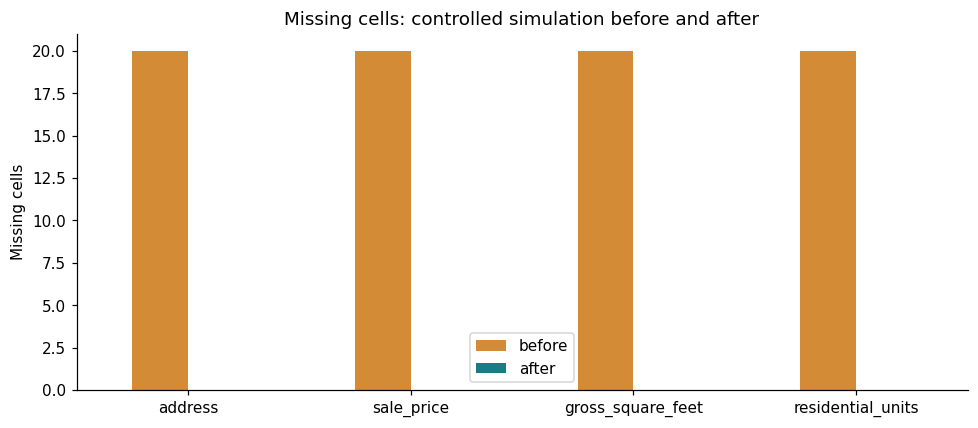

,neighborhood,building_class,records,address_present,price_present,area_present,units_present,positive_price_area,field_completeness_pct
0,FLATBUSH-NORTH,C3,113,113,113,113,113,50,100.0
1,BUSHWICK,C2,108,108,108,108,108,70,100.0
2,BOROUGH PARK,C3,105,105,105,105,105,45,100.0
3,BEDFORD STUYVESANT,C3,101,101,101,101,101,56,100.0
4,BENSONHURST,C3,84,84,84,84,84,45,100.0
5,BROWNSVILLE,C3,74,74,74,74,74,34,100.0
6,CROWN HEIGHTS,C1,65,65,65,65,65,40,100.0
7,BEDFORD STUYVESANT,C1,57,57,57,57,57,41,100.0


,record_id,neighborhood,sale_price,gross_square_feet
0,fa72f2c14eebc4b3d5a7,BATH BEACH,0.0,3000.0
1,46cb8290d24e965cb286,BATH BEACH,0.0,5082.0
2,7c00282f99f7107c2b5d,BATH BEACH,0.0,6000.0
5,297330fb05d5fb9ae449,BATH BEACH,0.0,3120.0
6,10e9e32a02b6805554a3,BATH BEACH,0.0,3120.0


In [7]:
comparison=pd.DataFrame({'before':missing_before,'after':after[fields].isna().sum()})
comparison.plot.bar(color=['#d38b35','#197b83'],title='Missing cells: controlled simulation before and after')
plt.ylabel('Missing cells');plt.xticks(rotation=0);plt.tight_layout();plt.show()
coverage=pd.read_sql_query((ROOT/'sql/coverage.sql').read_text(),con)
assert coverage.records.sum()==len(original)
display(coverage.head(8))
remaining=after[after.requires_review]
display(remaining[['record_id','neighborhood','sale_price','gross_square_feet']].head())


## 7. Prove reruns do not duplicate recoveries
Also compare the recovered audited fields against the original records; the goal is exact recovery, not an improved-looking estimate.

In [8]:
apply_proposal(con,'DEMO-000','DEMO_NOTEBOOK_REVIEWER')
assert con.execute('SELECT COUNT(*) FROM audit_log').fetchone()[0]==80
pd.testing.assert_frame_equal(original.set_index('record_id')[fields].sort_index(),after.set_index('record_id')[fields].sort_index())
print('Exact original-field recovery and idempotent reapplication confirmed.')


Exact original-field recovery and idempotent reapplication confirmed.


## 8. Findings and reviewer priorities

In [9]:
from IPython.display import Markdown
cells=len(original)*len(fields)
before_pct=100*(1-before.missing_fields.sum()/cells)
after_pct=100*(1-after.missing_fields.sum()/cells)
display(Markdown(f"""- **Controlled recovery:** {len(log)} source-matched fields restored; completeness changed from {before_pct:.2f}% to {after_pct:.2f}% across {cells:,} audited cells.
- **Protection:** one unsupported proposal rejected; reapplication created no duplicate audit entry.
- **Outstanding quality:** {len(remaining):,} records still trigger at least one business-rule flag, despite populated fields.
- **Priority:** verify consideration and area, investigate possible package transactions and preserve unresolved issues for appraiser review. Do not replace them with group averages.
- **Scope:** one official source and a local demonstration, not a production authorization system or independently verified valuation database."""))
con.close()
workspace.cleanup()


- **Controlled recovery:** 80 source-matched fields restored; completeness changed from 99.16% to 100.00% across 9,492 audited cells.
- **Protection:** one unsupported proposal rejected; reapplication created no duplicate audit entry.
- **Outstanding quality:** 1,216 records still trigger at least one business-rule flag, despite populated fields.
- **Priority:** verify consideration and area, investigate possible package transactions and preserve unresolved issues for appraiser review. Do not replace them with group averages.
- **Scope:** one official source and a local demonstration, not a production authorization system or independently verified valuation database.